# Step 5: Pre-specified evaluation, inference, 2026 event analysis, counterfactual
Run Steps 1 to 4 first. Needs `monthly_panel_with_hormuz_state.csv` in your `Dataset` folder. Runtime: a few minutes.

In [1]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Setup

In [2]:
import statsmodels.api as sm
from scipy.stats import rankdata
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

p = pd.read_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv")
p["month"] = pd.PeriodIndex(p["month"], freq="M"); p = p.set_index("month").sort_index().loc[:"2026-09"]
FEATS = ["oni_lag1", "oni_chg3", "nino34_lag1", "brent_ret1", "brent_ret3", "brent_z12", "gscpi_lag1", "gscpi_chg3"]

# PRE-SPECIFIED ANALYSIS PLAN (write this into the paper before looking at results)
H = 3                                        # primary horizon
TARGETS = {"GSCPI rise >= 0.5 SD": ("gscpi", 0.5), "Brent rise >= 10%": ("brent", 0.10)}
FIRST_YEAR, LAST_YEAR = 2012, 2025           # rolling-origin test years
MODELS = ["logistic", "grad_boost", "causal_structural"]

def label(kind, thr):
    if kind == "gscpi": fut = pd.concat([p["gscpi"].shift(-k) - p["gscpi"] for k in range(1, H + 1)], axis=1).max(axis=1); ok = p["gscpi"].shift(-H).notna()
    else: fut = pd.concat([p["brent"].shift(-k) / p["brent"] - 1 for k in range(1, H + 1)], axis=1).max(axis=1); ok = p["brent"].shift(-H).notna()
    return (fut >= thr).astype(float).where(ok)

d = pd.DataFrame({"g": p["gscpi"], "lb": np.log(p["brent"]), "oni": p["oni"]})
d["dg"] = d["g"].diff(); d["db"] = d["lb"].diff(); d["oni_l1"] = d["oni"].shift(1); d["dg_next"] = d["dg"].shift(-1); d["db_next"] = d["db"].shift(-1)
GC, BC = ["dg", "g", "db", "oni_l1"], ["db", "dg", "oni_l1"]
def fit_struct(end):
    s = d.loc["1999-01":end].dropna(subset=GC + ["dg_next", "db_next"])
    mg = sm.OLS(s["dg_next"], sm.add_constant(s[GC])).fit(); mb = sm.OLS(s["db_next"], sm.add_constant(s[BC])).fit()
    return mg, mb, np.column_stack([mg.resid.values, mb.resid.values])
def simulate(row, h, mg, mb, res, n=300, oni=None):
    oni = row["oni_l1"] if oni is None else oni
    idx = rng.integers(0, len(res), size=(n, h)); G = np.full(n, row["g"]); DG = np.full(n, row["dg"]); DB = np.full(n, row["db"]); LB = np.full(n, row["lb"])
    Gs, Bs = [], []
    for k in range(h):
        e = res[idx[:, k]]
        dgn = mg.params["const"] + mg.params["dg"] * DG + mg.params["g"] * G + mg.params["db"] * DB + mg.params["oni_l1"] * oni + e[:, 0]
        dbn = mb.params["const"] + mb.params["db"] * DB + mb.params["dg"] * DG + mb.params["oni_l1"] * oni + e[:, 1]
        G = G + dgn; LB = LB + dbn; DG, DB = dgn, dbn; Gs.append(G.copy()); Bs.append(np.exp(LB))
    return np.array(Gs), np.array(Bs)       # shape (h, n)

## 2. Rolling-origin predictions for the pre-specified family

In [3]:
mk = {"logistic": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
      "grad_boost": lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=0)}
preds = []
for tname, (kind, thr) in TARGETS.items():
    y = label(kind, thr)
    for yr in range(FIRST_YEAR, LAST_YEAR + 1):
        cut = pd.Period(f"{yr-1}-12", freq="M") - H
        tr = p.index[(p.index >= "1999-01") & (p.index <= cut)]; tr = tr[y.reindex(tr).notna().values]
        te = p.index[(p.index >= f"{yr}-01") & (p.index <= f"{yr}-12")]; te = te[y.reindex(te).notna().values]
        if y.loc[tr].sum() < 5 or len(te) == 0: continue
        out = {m: mk[m]().fit(p.loc[tr, FEATS], y.loc[tr]).predict_proba(p.loc[te, FEATS])[:, 1] for m in mk}
        mg, mb, res = fit_struct(pd.Period(f"{yr-1}-11", freq="M")); sp = []
        for t in te:
            if d.loc[t, ["dg", "g", "db", "oni_l1"]].isna().any(): sp.append(np.nan); continue
            Gs, Bs = simulate(d.loc[t], H, mg, mb, res)
            sp.append(float(((Gs.max(0) - d.loc[t, "g"]) >= thr).mean()) if kind == "gscpi" else float(((Bs.max(0) / np.exp(d.loc[t, "lb"]) - 1) >= thr).mean()))
        out["causal_structural"] = sp
        for m, pr in out.items():
            preds.append(pd.DataFrame({"target": tname, "model": m, "month": te, "y": y.loc[te].values, "p": pr, "base": y.loc[tr].mean()}))
pred = pd.concat(preds, ignore_index=True).dropna(subset=["p"]); pred.to_csv(f"{BASE}/primary_predictions.csv", index=False)

## 3. Inference: block bootstrap cis, circular-shift permutation test, holm correction

In [4]:
def auc(y, s):
    r = rankdata(s); n1 = y.sum(); n0 = len(y) - n1
    return np.nan if n1 == 0 or n0 == 0 else (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def bss(y, s, b): return 1 - np.mean((y - s) ** 2) / np.mean((y - b) ** 2)
B, BL = 2000, 6
rows = []
for (tname, m), g in pred.groupby(["target", "model"]):
    g = g.sort_values("month"); y, s, b = g.y.values, g.p.values, g.base.values; n = len(y)
    a0, b0 = auc(y, s), bss(y, s, b)
    ba, bb = [], []
    for _ in range(B):                                   # moving-block bootstrap (block = 6 months)
        starts = rng.integers(0, n - BL + 1, size=int(np.ceil(n / BL))); ix = np.concatenate([np.arange(k, k + BL) for k in starts])[:n]
        v = auc(y[ix], s[ix]); ba.append(v) if not np.isnan(v) else None; bb.append(bss(y[ix], s[ix], b[ix]))
    perm = [auc(np.roll(y, int(k)), s) for k in rng.integers(6, n - 6, size=B)]   # circular shifts keep the autocorrelation of y
    pval = (np.sum(np.array(perm) >= a0) + 1) / (B + 1)
    rows.append(dict(target=tname, model=m, n=n, pos_rate=round(y.mean(), 2), auc=round(a0, 3), auc_ci95=f"[{np.percentile(ba, 2.5):.2f}, {np.percentile(ba, 97.5):.2f}]",
                     brier_skill=round(b0, 3), bss_ci95=f"[{np.percentile(bb, 2.5):.2f}, {np.percentile(bb, 97.5):.2f}]", p_perm=round(pval, 3)))
prim = pd.DataFrame(rows)
order = prim["p_perm"].rank(method="first").astype(int)       # Holm step-down over the 6 pre-specified tests
m_ = len(prim); srt = prim["p_perm"].sort_values(); holm = {}; run = 0
for i, (ix, pv) in enumerate(srt.items()): run = max(run, min(1, (m_ - i) * pv)); holm[ix] = run
prim["p_holm"] = pd.Series(holm).round(3); print(prim.to_string(index=False)); prim.to_csv(f"{BASE}/primary_results.csv", index=False)

              target             model   n  pos_rate   auc     auc_ci95  brier_skill       bss_ci95  p_perm  p_holm
   Brent rise >= 10% causal_structural 168      0.33 0.501 [0.36, 0.59]       -0.012  [-0.11, 0.07]   0.487       1
   Brent rise >= 10%        grad_boost 168      0.33 0.624 [0.50, 0.71]       -0.026  [-0.26, 0.13]   0.000       0
   Brent rise >= 10%          logistic 168      0.33 0.531 [0.39, 0.63]       -0.004  [-0.12, 0.08]   0.399       1
GSCPI rise >= 0.5 SD causal_structural 168      0.23 0.489 [0.33, 0.67]       -0.106  [-0.26, 0.06]   0.528       1
GSCPI rise >= 0.5 SD        grad_boost 168      0.23 0.476 [0.35, 0.61]       -0.213 [-0.42, -0.04]   0.629       1
GSCPI rise >= 0.5 SD          logistic 168      0.23 0.445 [0.31, 0.59]       -0.147 [-0.31, -0.02]   0.736       1


## 4. Event inference for the 2026 shock

In [5]:
lb = np.log(p["brent"]); rows = []
for w in (1, 2, 3):
    for nm, s in (("Brent log change", lb.diff(w)), ("GSCPI change", p["gscpi"].diff(w))):
        post = s.loc["2026-03":"2026-06"]; t_star = post.idxmax(); hist = s.loc[:"2025-12"].dropna()
        rows.append(dict(window_months=w, series=nm, month_of_max=str(t_star), value=round(float(post.max()), 3),
                         hist_sd=round(float(hist.std()), 3), z=round(float((post.max() - hist.mean()) / hist.std()), 1),
                         hist_percentile=round(float((hist < post.max()).mean()) * 100, 1), hist_max=round(float(hist.max()), 3)))
evt = pd.DataFrame(rows); print(evt.to_string(index=False)); evt.to_csv(f"{BASE}/event_inference.csv", index=False)

 window_months           series month_of_max  value  hist_sd   z  hist_percentile  hist_max
             1 Brent log change      2026-03  0.375    0.103 3.6             99.7     0.469
             1     GSCPI change      2026-04  1.155    0.369 3.1             99.4     1.429
             2 Brent log change      2026-04  0.504    0.161 3.1             99.7     0.784
             2     GSCPI change      2026-04  1.294    0.545 2.4             99.1     2.672
             3 Brent log change      2026-04  0.566    0.199 2.8             99.7     0.856
             3     GSCPI change      2026-04  1.422    0.662 2.1             99.4     3.504


## 5. Counterfactual (no-shock) path vs observed, mar-sep 2026

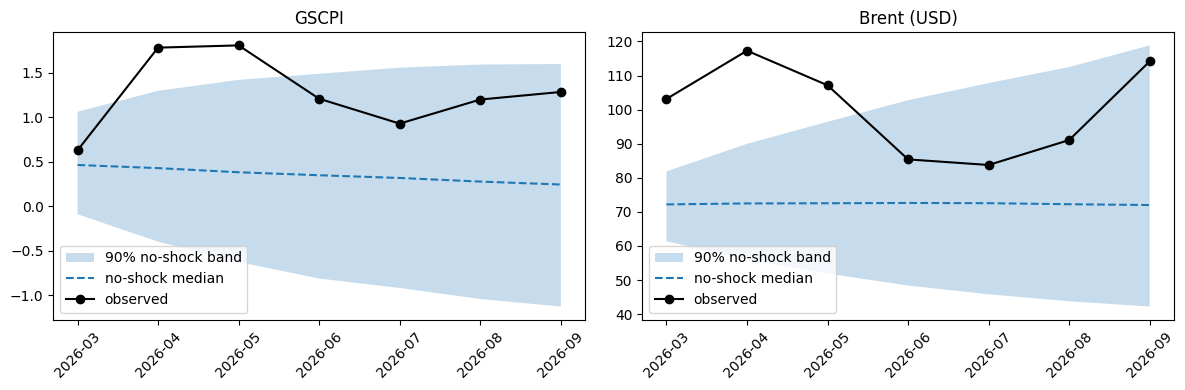

     series   month  observed  nochange_median          band90  outside_band
      GSCPI 2026-03      0.63             0.46   [-0.09, 1.06]         False
      GSCPI 2026-04      1.78             0.43   [-0.40, 1.30]          True
      GSCPI 2026-05      1.81             0.38   [-0.63, 1.42]          True
      GSCPI 2026-06      1.21             0.35   [-0.81, 1.49]         False
      GSCPI 2026-07      0.93             0.32   [-0.92, 1.56]         False
      GSCPI 2026-08      1.20             0.28   [-1.04, 1.59]         False
      GSCPI 2026-09      1.28             0.24   [-1.13, 1.60]         False
Brent (USD) 2026-03    103.13            72.20  [61.38, 81.88]          True
Brent (USD) 2026-04    117.29            72.48  [55.98, 89.97]          True
Brent (USD) 2026-05    107.14            72.53  [51.90, 96.43]          True
Brent (USD) 2026-06     85.40            72.62 [48.39, 102.77]         False
Brent (USD) 2026-07     83.76            72.55 [45.82, 107.79]         False

In [6]:
mg, mb, res = fit_struct("2025-12"); r0 = d.loc[pd.Period("2026-02", freq="M")].copy()
oni_last = float(d["oni"].dropna().iloc[-1]); Gs, Bs = simulate(r0, 7, mg, mb, res, n=5000, oni=oni_last)
months = pd.period_range("2026-03", "2026-09", freq="M")
fig, axs = plt.subplots(1, 2, figsize=(12, 4)); cf = []
for ax, (nm, sims, obs) in zip(axs, [("GSCPI", Gs, p["gscpi"]), ("Brent (USD)", Bs, p["brent"])]):
    lo, md, hi = np.percentile(sims, [5, 50, 95], axis=1); x = [str(m) for m in months]
    ax.fill_between(x, lo, hi, alpha=0.25, label="90% no-shock band"); ax.plot(x, md, "--", label="no-shock median"); ax.plot(x, obs.loc[months].values, "o-", color="k", label="observed")
    ax.set_title(nm); ax.tick_params(axis="x", rotation=45); ax.legend()
    for i, m in enumerate(months): cf.append(dict(series=nm, month=str(m), observed=round(float(obs.loc[m]), 2), nochange_median=round(float(md[i]), 2), band90=f"[{lo[i]:.2f}, {hi[i]:.2f}]", outside_band=bool(obs.loc[m] > hi[i] or obs.loc[m] < lo[i])))
fig.tight_layout(); fig.savefig(f"{BASE}/counterfactual_2026.png", dpi=150); plt.show()
cf = pd.DataFrame(cf); print(cf.to_string(index=False)); cf.to_csv(f"{BASE}/counterfactual_2026.csv", index=False)